# A Leakage-Aware Evaluation of Machine Learning Classifiers for Multi-Class Attack Detection in Wireless Sensor Networks

**Companion notebook to the paper** &nbsp;·&nbsp; Muhammad Hanzala Dawood &nbsp;·&nbsp; Department of Computer Science, University of Peshawar

This notebook reproduces every figure, table and number reported in the paper, using the [WSN-DS dataset](https://doi.org/10.1155/2016/4731953) (374,661 records, five classes: Normal, Grayhole, Blackhole, TDMA, Flooding).

---

## Contents

| # | Section | What it produces for the paper |
|---|---|---|
| 1 | Setup | Configuration, readable attribute names, helper functions |
| 2 | Data loading and quality checks | Missing and placeholder values, raw class distribution |
| 3 | Exploratory data analysis | Attribute table, class-mean table, log-transform, correlation and box-plot figures |
| 4 | Data cleaning | Identifier removal, de-duplication, cluster-head diagnostics |
| 5 | Held-out pipeline (80/20) | Scaling, SMOTE, class-distribution table, seven trained models |
| 6 | Held-out analyses | Confusion matrix, feature importance, McNemar test, SMOTE trade-off |
| 7 | Cross-validation experiments | Full pipeline plus four ablation and robustness settings |
| 8 | Results tables | Cross-validation, per-class and robustness tables |
| 9 | Export | `paper_assets.zip` |

## How to run

1. Open the notebook in Google Colab and upload `WSN-DS.csv` to `/content/` (or change `DATA_PATH` in Section 1.3).
2. Run all cells from top to bottom.
3. Section 7 is the slow part (about 1.5 hours on a Colab CPU runtime). Each finished model/fold is saved to Google Drive, so after a disconnect re-run Sections 1, 2, 4 and 7: finished runs are skipped.
4. Extract the downloaded `paper_assets.zip` into the `Visualization/` folder next to `main.tex`.

---
# 1. Setup

### 1.1 Mount Google Drive
The cross-validation experiments in Section 7 save every finished run to Google Drive, so no work is lost if Colab disconnects. Skip this cell to keep results in the local session only.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1.2 Imports

In [3]:
import os
import time
import pickle
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from scipy.stats import skew
from imblearn.over_sampling import SMOTE
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_recall_fscore_support

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
print('Libraries loaded.')

Libraries loaded.


### 1.3 Configuration
Paths, random seed, model lists and the readable attribute names used in the paper are defined once here and reused by every section.

In [4]:
SEED = 42
N_FOLDS = 5
DATA_PATH = '/content/WSN-DS.csv'

# Every figure, table and result used by the paper is written here and zipped in Section 9
ASSET_DIR = '/content/paper_assets'
FIG_DIR = f'{ASSET_DIR}/figures'
TAB_DIR = f'{ASSET_DIR}/tables'
RES_DIR = f'{ASSET_DIR}/results'
for d in (FIG_DIR, TAB_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

# Cross-validation runs are cached on Drive when it is mounted, so a disconnect loses no work
RUN_DIR = '/content/drive/MyDrive/WSN-DS-results' if os.path.isdir('/content/drive/MyDrive') else RES_DIR
os.makedirs(RUN_DIR, exist_ok=True)
RES_FILE = f'{RUN_DIR}/robustness_runs.csv'

ID_COLS = ['id', 'who CH', 'Time']
CLASS_ORDER = ['Normal', 'Grayhole', 'Blackhole', 'TDMA', 'Flooding']
LABELS = [0, 1, 2, 3, 4]
CLASS_MAP = dict(zip(CLASS_ORDER, LABELS))

# Dataset column -> (name used in the paper, description)
FEATURES = {
    'Is_CH':           ('CH Flag',             'Node is a cluster head (CH) in the current round'),
    'Dist_To_CH':      ('Node-to-CH Distance', 'Distance between the node and its CH'),
    'ADV_S':           ('Adverts Sent',        'CH advertisement messages broadcast'),
    'ADV_R':           ('Adverts Received',    'CH advertisement messages received'),
    'JOIN_S':          ('Joins Sent',          'Join-request messages sent to a CH'),
    'JOIN_R':          ('Joins Received',      'Join-request messages received by a CH'),
    'SCH_S':           ('Schedules Sent',      'TDMA schedule messages broadcast by a CH'),
    'SCH_R':           ('Schedules Received',  'TDMA schedule messages received from a CH'),
    'Rank':            ('TDMA Slot',           'Position of the node in the TDMA schedule'),
    'DATA_S':          ('Packets Sent',        'Data packets sent to the CH'),
    'DATA_R':          ('Packets Received',    'Data packets received'),
    'Data_Sent_To_BS': ('Packets to BS',       'Data packets forwarded to the base station (BS)'),
    'dist_CH_To_BS':   ('CH-to-BS Distance',   'Distance between the CH and the BS'),
    'send_code':       ('Send Code',           'Cluster transmission code'),
    'Expaned Energy':  ('Energy Consumed',     'Energy consumed in the previous round'),
}
feat_cols = list(FEATURES)

ROBUST_COLS = ['DATA_S', 'Expaned Energy']
MINMAX_COLS = ['Dist_To_CH', 'Rank']
LOG_COLS = ['DATA_R', 'Data_Sent_To_BS', 'dist_CH_To_BS']
SCALING = {**dict.fromkeys(ROBUST_COLS, 'Robust'),
           **dict.fromkeys(MINMAX_COLS, 'Min-Max'),
           **dict.fromkeys(LOG_COLS, 'Log + Min-Max')}

ALL_MODELS = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'XGBoost', 'SVM (RBF)', 'Naive Bayes']
KEY_MODELS = ['Logistic Regression', 'KNN', 'Random Forest', 'XGBoost']

# Figures are sized for one IEEE column (3.5 in) so their text stays readable in the PDF
COL_W = 3.5
plt.rcParams.update({
    'font.family': 'serif', 'font.size': 8, 'axes.titlesize': 8,
    'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
})
PALETTE = dict(zip(CLASS_ORDER, sns.color_palette('colorblind', 5)))

print('Run log:', RES_FILE)

Run log: /content/drive/MyDrive/WSN-DS-results/robustness_runs.csv


### 1.4 Helper functions

| Function | Purpose |
|---|---|
| `nice()` | Paper name of a dataset column |
| `save_table()` | Writes a LaTeX `tabular` that `main.tex` includes with `\input` |
| `scale()` | Distribution-aware scaling; every scaler is fitted on the training part only |
| `make_model()`, `fit_model()` | The seven classifiers with default settings (no tuning) |

In [5]:
def nice(col):
    return FEATURES[col][0]


def tex(s):
    return s.replace('_', r'\_')


def bold(s):
    return rf'\textbf{{{s}}}'


def save_table(name, colspec, header, rows):
    lines = [rf'\begin{{tabular}}{{{colspec}}}', r'\toprule',
             ' & '.join(bold(h) for h in header) + r' \\', r'\midrule']
    lines += [' & '.join(map(str, row)) + r' \\' for row in rows]
    lines += [r'\bottomrule', r'\end{tabular}']
    with open(f'{TAB_DIR}/{name}', 'w') as f:
        f.write('\n'.join(lines) + '\n')
    print(f'Saved tables/{name}')


def scale(X_tr, X_te):
    X_tr, X_te = X_tr.copy(), X_te.copy()
    for cols, scaler in [(ROBUST_COLS, RobustScaler()), (MINMAX_COLS, MinMaxScaler())]:
        X_tr[cols] = scaler.fit_transform(X_tr[cols])
        X_te[cols] = scaler.transform(X_te[cols])
    log_scaler = MinMaxScaler()
    X_tr[LOG_COLS] = log_scaler.fit_transform(np.log1p(X_tr[LOG_COLS]))
    X_te[LOG_COLS] = log_scaler.transform(np.log1p(X_te[LOG_COLS]))
    return X_tr, X_te


def make_model(name):
    return {
        'Logistic Regression': lambda: LogisticRegression(solver='liblinear', max_iter=1000, random_state=SEED),
        'KNN': lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        'Decision Tree': lambda: DecisionTreeClassifier(random_state=SEED),
        'Random Forest': lambda: RandomForestClassifier(random_state=SEED, n_jobs=-1),
        'XGBoost': lambda: xgb.XGBClassifier(objective='multi:softmax', num_class=5, random_state=SEED, n_jobs=-1),
        'SVM (RBF)': lambda: SVC(kernel='rbf', random_state=SEED),
        'Naive Bayes': lambda: GaussianNB(),
    }[name]()


def fit_model(name, X, y):
    # An RBF SVM on >1M SMOTE rows is impractical, so it is trained on a stratified 10% subsample
    if name == 'SVM (RBF)':
        X, _, y, _ = train_test_split(X, y, train_size=0.1, stratify=y, random_state=SEED)
    return make_model(name).fit(X, y)


print('Helpers ready.')

Helpers ready.


---
# 2. Data Loading and Quality Checks

### 2.1 Load the raw data

In [6]:
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()
print(f'{df_raw.shape[0]:,} records x {df_raw.shape[1]} columns')
df_raw.head()

374,661 records x 19 columns


,id,Time,Is_CH,who CH,Dist_To_CH,ADV_S,ADV_R,JOIN_S,JOIN_R,SCH_S,SCH_R,Rank,DATA_S,DATA_R,Data_Sent_To_BS,dist_CH_To_BS,send_code,Expaned Energy,Attack type
0,101000,50,1,101000,0.0000,1,0,0,25,1,0,0,0,1200,48,130.0854,0,2.4694,Normal
1,101001,50,0,101044,75.3234,0,4,1,0,0,1,2,38,0,0,0.0000,4,0.0696,Normal
2,101002,50,0,101010,46.9545,0,4,1,0,0,1,19,41,0,0,0.0000,3,0.0690,Normal
3,101003,50,0,101044,64.8523,0,4,1,0,0,1,16,38,0,0,0.0000,4,0.0667,Normal
4,101004,50,0,101010,4.8334,0,4,1,0,0,1,25,41,0,0,0.0000,3,0.0653,Normal


### 2.2 Column quality summary
Data type, missing values, distinct values and the number of `0` and `-1` entries (common placeholders for missing sensor readings) in every column. No column has missing values; the zeros reflect normal protocol behaviour, e.g. the CH Flag is 0 for every node that is not a cluster head.

In [7]:
pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing': df_raw.isna().sum(),
    'unique': df_raw.nunique(),
    'zeros': (df_raw == 0).sum(),
    'minus ones': (df_raw == -1).sum(),
})

,dtype,missing,unique,zeros,minus ones
id,int64,0,11120,0,0
Time,int64,0,196,0,0
Is_CH,int64,0,2,331288,0
who CH,int64,0,7088,0,0
Dist_To_CH,float64,0,13956,82502,0
ADV_S,int64,0,85,331288,0
ADV_R,int64,0,31,33351,0
JOIN_S,int64,0,2,82461,0
JOIN_R,int64,0,101,355792,0
SCH_S,int64,0,95,355804,0


### 2.3 Raw class distribution
Normal traffic makes up over 90% of the records, so accuracy alone is misleading; the paper uses the macro F1-score as its main metric.

In [8]:
counts = df_raw['Attack type'].value_counts().reindex(CLASS_ORDER)
pd.DataFrame({'records': counts, 'share (%)': (100 * counts / counts.sum()).round(2)})

,records,share (%)
Attack type,,
Normal,340066,90.7700
Grayhole,14596,3.9000
Blackhole,10049,2.6800
TDMA,6638,1.7700
Flooding,3312,0.8800


---
# 3. Exploratory Data Analysis
As stated in the paper, all statistics in this section describe the **raw data**: the three identifier columns are set aside, but duplicates are kept.

In [9]:
df_eda = df_raw.drop(columns=ID_COLS)
assert set(feat_cols) == set(df_eda.columns) - {'Attack type'}
print(f'{len(df_eda):,} records x {len(feat_cols)} attributes')

374,661 records x 15 attributes


### 3.1 Attribute table
**Paper:** attribute table (`tables/features.tex`).

In [10]:
attr = pd.DataFrame({
    'Feature': [nice(c) for c in feat_cols],
    'Dataset column': feat_cols,
    'Description': [FEATURES[c][1] for c in feat_cols],
    'Unique': [df_eda[c].nunique() for c in feat_cols],
    'Skew': [skew(df_eda[c]) for c in feat_cols],
    'Scaling': [SCALING.get(c, 'None') for c in feat_cols],
})
display(attr.round(2))

rows = [[f, rf'\texttt{{{tex(c)}}}', d, f'{u:,}', f'{s:.2f}', sc] for f, c, d, u, s, sc in attr.itertuples(index=False)]
save_table('features.tex', 'llp{5.6cm}rrl', attr.columns, rows)

,Feature,Dataset column,Description,Unique,Skew,Scaling
0,CH Flag,Is_CH,Node is a cluster head (CH) in the current round,2,2.4000,None
1,Node-to-CH Distance,Dist_To_CH,Distance between the node and its CH,13956,1.6600,Min-Max
2,Adverts Sent,ADV_S,CH advertisement messages broadcast,85,19.4400,None
3,Adverts Received,ADV_R,CH advertisement messages received,31,2.2900,None
4,Joins Sent,JOIN_S,Join-request messages sent to a CH,2,-1.3500,None
5,Joins Received,JOIN_R,Join-request messages received by a CH,101,9.7800,None
6,Schedules Sent,SCH_S,TDMA schedule messages broadcast by a CH,95,15.9000,None
7,Schedules Received,SCH_R,TDMA schedule messages received from a CH,2,-1.1400,None
8,TDMA Slot,Rank,Position of the node in the TDMA schedule,100,2.4000,Min-Max
9,Packets Sent,DATA_S,Data packets sent to the CH,192,1.5700,Robust


Saved tables/features.tex


### 3.2 Mean attribute value per class
**Paper:** class-mean table (`tables/class_means.tex`). Shows how each attack shifts the network away from normal behaviour.

In [11]:
means = df_eda.groupby('Attack type')[feat_cols].mean().T[CLASS_ORDER]
means.index = [nice(c) for c in means.index]
display(means.round(2))

save_table('class_means.tex', 'lrrrrr', ['Feature'] + CLASS_ORDER,
           [[feat] + [f'{v:,.2f}' for v in row] for feat, row in means.iterrows()])

Attack type,Normal,Grayhole,Blackhole,TDMA,Flooding
CH Flag,0.0300,1.0000,1.0000,0.9400,1.0000
Node-to-CH Distance,24.8600,0.0000,0.0000,1.7800,0.0000
Adverts Sent,0.0400,1.0000,1.0000,0.9400,17.1200
Adverts Received,5.9900,19.0000,17.0800,5.3200,24.0000
Joins Sent,0.8600,0.0000,0.0000,0.0600,0.0000
Joins Received,0.2200,3.0400,5.1900,14.4100,2.5200
Schedules Sent,0.0200,0.2100,0.3700,14.4100,0.1700
Schedules Received,0.8200,0.0000,0.0200,0.0600,0.1900
TDMA Slot,10.6500,0.0000,0.0000,1.1300,0.0000
Packets Sent,49.3600,0.0000,0.0000,3.0900,0.0000


Saved tables/class_means.tex


### 3.3 Effect of the log transform
**Paper:** log-transform figure (`figures/fig_log_transform.png`). The three most skewed traffic attributes before (top) and after (bottom) $\log(1+x)$.

Packets Received   skew raw =  3.60   skew log(1+x) =  2.10
Packets to BS      skew raw =  7.85   skew log(1+x) =  2.19
CH-to-BS Distance  skew raw =  1.94   skew log(1+x) =  1.70


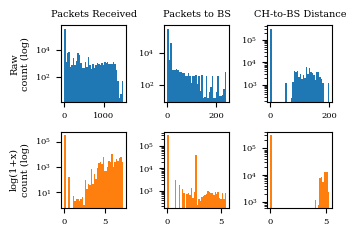

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(COL_W, 2.4))
for j, col in enumerate(LOG_COLS):
    raw = df_eda[col]
    axes[0, j].hist(raw, bins=40, color='tab:blue')
    axes[1, j].hist(np.log1p(raw), bins=40, color='tab:orange')
    axes[0, j].set_title(nice(col), fontsize=7)
    for ax in axes[:, j]:
        ax.set_yscale('log')
        ax.tick_params(labelsize=6)
    print(f'{nice(col):<18} skew raw = {skew(raw):5.2f}   skew log(1+x) = {skew(np.log1p(raw)):5.2f}')
axes[0, 0].set_ylabel('Raw\ncount (log)', fontsize=7)
axes[1, 0].set_ylabel('log(1+x)\ncount (log)', fontsize=7)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_log_transform.png')
plt.show()

### 3.4 Feature correlation
**Paper:** correlation figure (`figures/fig_correlation.png`). The table lists the ten most strongly correlated attribute pairs.

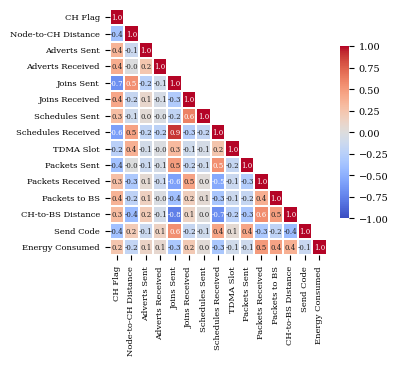

,,Pearson r
Schedules Received,Joins Sent,0.9000
CH-to-BS Distance,Joins Sent,-0.7600
Joins Sent,CH Flag,-0.6800
CH-to-BS Distance,Schedules Received,-0.6800
Schedules Sent,Joins Received,0.6100
Schedules Received,CH Flag,-0.6000
Packets Received,Joins Sent,-0.5900
CH-to-BS Distance,Packets Received,0.5500
Send Code,Joins Sent,0.5500
Joins Sent,Node-to-CH Distance,0.5500


In [13]:
corr = df_eda[feat_cols].rename(columns=nice).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(COL_W, 3.2))
sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.1f',
            annot_kws={'size': 5}, linewidths=0.3, cbar_kws={'shrink': 0.7}, ax=ax)
ax.tick_params(labelsize=6)
fig.savefig(f'{FIG_DIR}/fig_correlation.png')
plt.show()

pairs = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10).round(2).to_frame('Pearson r')

### 3.5 Most discriminative attributes by class
**Paper:** box-plot figure (`figures/fig_boxplots_by_attack.png`). Attributes are ranked by mutual information with the attack label on a class-balanced sample (3,000 records per class), and the four highest-ranked non-binary attributes are plotted.

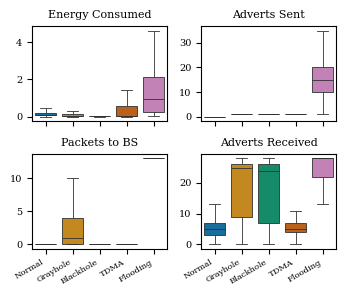

,mutual information
Energy Consumed,0.9100
Adverts Sent,0.8760
Packets to BS,0.5940
Adverts Received,0.5480
CH-to-BS Distance,0.5010
CH Flag,0.4330
Schedules Sent,0.4270
Packets Sent,0.3940
TDMA Slot,0.3570
Joins Sent,0.3540


In [14]:
# Class-balanced sample so the ranking reflects differences between attacks, not the Normal majority
sample = df_eda.groupby('Attack type').sample(n=3000, random_state=SEED)
mi = pd.Series(mutual_info_classif(sample[feat_cols], sample['Attack type'], random_state=SEED),
               index=feat_cols).sort_values(ascending=False)
top4 = [c for c in mi.index if df_eda[c].nunique() > 2][:4]

fig, axes = plt.subplots(2, 2, figsize=(COL_W, 3.0), sharex=True)
for ax, col in zip(axes.flat, top4):
    sns.boxplot(data=df_eda, x='Attack type', y=col, order=CLASS_ORDER, hue='Attack type',
                hue_order=CLASS_ORDER, palette=PALETTE, legend=False, showfliers=False,
                linewidth=0.6, ax=ax)
    ax.set_title(nice(col))
    ax.set_xlabel('')
    ax.set_ylabel('')
for ax in axes[1]:
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right', fontsize=6)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_boxplots_by_attack.png')
plt.show()

mi.rename(index=nice).round(3).to_frame('mutual information')

---
# 4. Data Cleaning
The three identifier columns (`id`, `who CH`, `Time`) are excluded from the model inputs, and exact duplicate records are removed **before any split**, so identical records cannot appear in both training and test data. The `id` column is kept aside only to derive the sensor-node number used for node-grouped cross-validation (Section 7.6).

In [15]:
df = df_raw.copy()
df['label'] = df['Attack type'].map(CLASS_MAP)
df = df.drop_duplicates(subset=feat_cols + ['label']).reset_index(drop=True)
# The last three digits of each record id are the sensor-node number
df['node'] = df['id'] % 1000
assert len(df) == 333_521, len(df)

removed = len(df_raw) - len(df)
n_nodes = df['node'].nunique()
print(f'Records: {len(df_raw):,} -> {len(df):,} ({removed:,} duplicates removed, {100 * removed / len(df_raw):.1f}%)')
print(f'Model inputs: {len(feat_cols)} attributes | sensor nodes: {n_nodes}')

Records: 374,661 -> 333,521 (41,140 duplicates removed, 11.0%)
Model inputs: 15 attributes | sensor nodes: 100


### 4.1 Cluster-head diagnostics
Every Grayhole, Blackhole and Flooding record comes from a cluster head, but some TDMA records do not. This explains why TDMA is the hardest class (Section 6.1) and motivates the cluster-head-only experiment (Section 7.5).

In [16]:
role = df['Is_CH'].map({0: 'Member node', 1: 'Cluster head'})
ch = pd.crosstab(df['Attack type'], role).reindex(CLASS_ORDER)[['Cluster head', 'Member node']]
ch['Cluster head (%)'] = (100 * ch['Cluster head'] / ch[['Cluster head', 'Member node']].sum(axis=1)).round(1)
ch

Is_CH,Cluster head,Member node,Cluster head (%)
Attack type,,,
Normal,8372,301165,2.7000
Grayhole,10844,0,100.0000
Blackhole,4225,0,100.0000
TDMA,5339,423,92.7000
Flooding,3153,0,100.0000


---
# 5. Held-out Pipeline (80/20 Split)
The main comparison in the paper uses cross-validation (Section 7). This single stratified split provides one fixed test set for the confusion matrix, feature importance, the McNemar test and the SMOTE trade-off analysis.

### 5.1 Split, scale and oversample
Scalers and SMOTE are fitted on the training partition only; the test set keeps its natural class distribution.

In [17]:
# Unscaled count columns stay integer, as in the original pipeline: SMOTE then rounds their synthetic values down
X = df[feat_cols].astype(dict.fromkeys(ROBUST_COLS + MINMAX_COLS + LOG_COLS, float))
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train_s, X_test_s = scale(X_train, X_test)
X_train_sm, y_train_sm = SMOTE(random_state=SEED).fit_resample(X_train_s, y_train)
y_true = y_test.to_numpy()

print(f'Train: {len(X_train):,} | Test: {len(X_test):,} | Train after SMOTE: {len(X_train_sm):,}')

Train: 266,816 | Test: 66,705 | Train after SMOTE: 1,238,145


### 5.2 Class distribution at each stage
**Paper:** class-distribution table.

In [18]:
stages = {
    'Raw': df_raw['Attack type'].map(CLASS_MAP),
    'De-dup.': df['label'],
    'Train': y_train,
    'Test': y_test,
    'SMOTE': y_train_sm,
}
dist = pd.DataFrame({k: pd.Series(v).value_counts().reindex(LABELS).to_numpy() for k, v in stages.items()},
                    index=CLASS_ORDER)
dist.loc['Total'] = dist.sum()
dist

,Raw,De-dup.,Train,Test,SMOTE
Normal,340066,309537,247629,61908,247629
Grayhole,14596,10844,8675,2169,247629
Blackhole,10049,4225,3380,845,247629
TDMA,6638,5762,4610,1152,247629
Flooding,3312,3153,2522,631,247629
Total,374661,333521,266816,66705,1238145


### 5.3 Train the seven classifiers
Default hyperparameters, no tuning. These single-split scores are for reference only; the paper reports the cross-validated results from Section 8.

In [19]:
models, preds = {}, {}
for name in ALL_MODELS:
    t0 = time.perf_counter()
    models[name] = fit_model(name, X_train_sm, y_train_sm)
    preds[name] = np.asarray(models[name].predict(X_test_s))
    print(f'{name:<20} trained and evaluated in {time.perf_counter() - t0:6.1f} s')

holdout = pd.DataFrame({
    name: {'Accuracy': accuracy_score(y_true, p),
           'Weighted F1': f1_score(y_true, p, average='weighted'),
           'Macro F1': f1_score(y_true, p, average='macro')}
    for name, p in preds.items()
}).T
holdout.sort_values('Macro F1', ascending=False)

Logistic Regression  trained and evaluated in   30.9 s
KNN                  trained and evaluated in   10.9 s
Decision Tree        trained and evaluated in    8.0 s
Random Forest        trained and evaluated in  112.2 s
XGBoost              trained and evaluated in   44.4 s
SVM (RBF)            trained and evaluated in  171.9 s
Naive Bayes          trained and evaluated in    0.8 s


,Accuracy,Weighted F1,Macro F1
XGBoost,0.9941,0.9942,0.9580
Random Forest,0.9933,0.9934,0.9546
Decision Tree,0.9897,0.9901,0.9354
Logistic Regression,0.9690,0.9725,0.8852
SVM (RBF),0.9697,0.9726,0.8784
KNN,0.9717,0.9745,0.8743
Naive Bayes,0.9238,0.9380,0.7108


---
# 6. Held-out Analysis

### 6.1 XGBoost confusion matrix
**Paper:** confusion-matrix figure (`figures/fig_confusion_xgb.png`) and the error analysis of XGBoost.

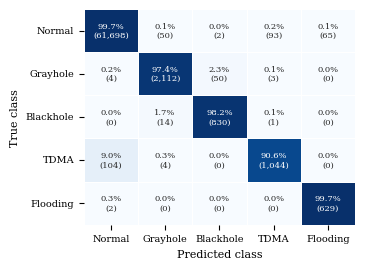

False alarms  : 210 of 61,908 Normal records
Missed attacks: 110 of 4,797 attack records


,Normal,Grayhole,Blackhole,TDMA,Flooding
Normal,61698,50,2,93,65
Grayhole,4,2112,50,3,0
Blackhole,0,14,830,1,0
TDMA,104,4,0,1044,0
Flooding,2,0,0,0,629


In [20]:
cm = confusion_matrix(y_true, preds['XGBoost'], labels=LABELS)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
annot = np.array([[f'{p:.1f}%\n({n:,})' for p, n in zip(prow, nrow)] for prow, nrow in zip(cm_pct, cm)])

fig, ax = plt.subplots(figsize=(COL_W, 2.8))
sns.heatmap(cm_pct, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=100, cbar=False,
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, annot_kws={'size': 6},
            linewidths=0.5, linecolor='white', ax=ax)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
plt.setp(ax.get_yticklabels(), rotation=0)
fig.savefig(f'{FIG_DIR}/fig_confusion_xgb.png')
plt.show()

print(f'False alarms  : {cm[0, 1:].sum()} of {cm[0].sum():,} Normal records')
print(f'Missed attacks: {cm[1:, 0].sum()} of {cm[1:].sum():,} attack records')
pd.DataFrame(cm, index=CLASS_ORDER, columns=CLASS_ORDER)

### 6.2 XGBoost feature importance
**Paper:** feature-importance figure (`figures/fig_xgb_importance.png`).

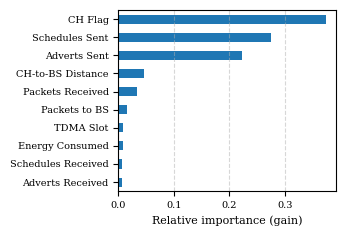

,gain
CH Flag,0.3732
Schedules Sent,0.2750
Adverts Sent,0.2219
CH-to-BS Distance,0.0455
Packets Received,0.0341
Packets to BS,0.0148
TDMA Slot,0.0075
Energy Consumed,0.0074
Schedules Received,0.0069
Adverts Received,0.0069


In [21]:
imp = pd.Series(models['XGBoost'].feature_importances_, index=feat_cols).rename(index=nice).sort_values()

fig, ax = plt.subplots(figsize=(COL_W, 2.4))
imp.tail(10).plot.barh(ax=ax, color='tab:blue')
ax.set_xlabel('Relative importance (gain)')
ax.grid(axis='x', linestyle='--', alpha=0.5)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_xgb_importance.png')
plt.show()

imp[::-1].round(4).to_frame('gain')

### 6.3 McNemar test
**Paper:** significance of the difference between XGBoost and Random Forest / Decision Tree (`results/mcnemar.txt`).

In [22]:
xgb_ok = preds['XGBoost'] == y_true
report = []
for other in ['Random Forest', 'Decision Tree']:
    other_ok = preds[other] == y_true
    table = [[np.sum(xgb_ok & other_ok), np.sum(xgb_ok & ~other_ok)],
             [np.sum(~xgb_ok & other_ok), np.sum(~xgb_ok & ~other_ok)]]
    res = mcnemar(table, exact=False, correction=True)
    report.append(f'XGBoost vs {other}: only XGBoost correct = {table[0][1]}, only {other} correct = {table[1][0]}, '
                  f'chi2 = {res.statistic:.2f}, p = {res.pvalue:.4g}')

print('\n'.join(report))
with open(f'{RES_DIR}/mcnemar.txt', 'w') as f:
    f.write('\n'.join(report) + '\n')

XGBoost vs Random Forest: only XGBoost correct = 143, only Random Forest correct = 89, chi2 = 12.11, p = 0.0005021
XGBoost vs Decision Tree: only XGBoost correct = 405, only Decision Tree correct = 112, chi2 = 164.92, p = 9.52e-38


### 6.4 Why SMOTE lowers macro F1
**Paper:** SMOTE paragraph of the robustness section (`results/smote_precision_recall.csv`). XGBoost and Random Forest are retrained without SMOTE and compared on missed attacks (attacks predicted as Normal), false alarms (Normal records predicted as an attack) and per-class precision and recall.

In [23]:
rows = []
for name in ['XGBoost', 'Random Forest']:
    pred_plain = np.asarray(fit_model(name, X_train_s, y_train).predict(X_test_s))
    for setting, pred in [('SMOTE', preds[name]), ('No SMOTE', pred_plain)]:
        missed = int(((y_true != 0) & (pred == 0)).sum())
        false_alarms = int(((y_true == 0) & (pred != 0)).sum())
        print(f'{name:<14} {setting:<9} missed attacks = {missed:4d}   false alarms = {false_alarms:4d}')
        p, r, _, _ = precision_recall_fscore_support(y_true, pred, labels=LABELS, zero_division=0)
        rows += [{'model': name, 'setting': setting, 'class': c, 'precision': pi, 'recall': ri}
                 for c, pi, ri in zip(CLASS_ORDER, p, r)]

pr = pd.DataFrame(rows).pivot_table(index=['model', 'class'], columns='setting', values=['precision', 'recall']).round(4)
pr.to_csv(f'{RES_DIR}/smote_precision_recall.csv')
pr

XGBoost        SMOTE     missed attacks =  110   false alarms =  210
XGBoost        No SMOTE  missed attacks =  185   false alarms =   87
Random Forest  SMOTE     missed attacks =  108   false alarms =  270
Random Forest  No SMOTE  missed attacks =  143   false alarms =  108


precision          recall       
setting                  No SMOTE  SMOTE No SMOTE  SMOTE
model         class                                     
Random Forest Blackhole    0.9599 0.9557   0.9633 0.9692
              Flooding     0.9224 0.9129   0.9794 0.9968
              Grayhole     0.9707 0.9607   0.9793 0.9806
              Normal       0.9977 0.9983   0.9983 0.9956
              TDMA         0.9792 0.8724   0.8976 0.9080
XGBoost       Blackhole    0.9583 0.9410   0.9787 0.9822
              Flooding     0.9360 0.9063   0.9271 0.9968
              Grayhole     0.9773 0.9688   0.9742 0.9737
              Normal       0.9970 0.9982   0.9986 0.9966
              TDMA         0.9819 0.9150   0.8941 0.9062

---
# 7. Cross-Validation Experiments
Every setting uses stratified 5-fold cross-validation on the de-duplicated data, with scaling and SMOTE fitted inside each training fold only.

| Run | Setting | Models | Used in the paper for |
|---|---|---|---|
| `full` | Scaling + SMOTE | All seven | Main results, per-class F1, computational cost |
| `no_smote` | Scaling only | LR, KNN, RF, XGBoost | SMOTE ablation |
| `no_scaling` | SMOTE only | LR, KNN, RF, XGBoost | Scaling ablation |
| `ch_only` | Cluster-head records, CH Flag removed | LR, KNN, RF, XGBoost | Node-role shortcut check |
| `node_grouped` | Folds grouped by sensor node | LR, KNN, RF, XGBoost | Generalization to unseen nodes |

> **Runtime:** about 1.5 hours in total on a Colab CPU runtime. Each finished model/fold is appended to `RES_FILE`, and re-running a cell skips everything already recorded. If `robustness_runs.csv` from an earlier session is already in `MyDrive/WSN-DS-results/`, these cells finish almost instantly.

### 7.1 Experiment runner

In [24]:
def run_experiment(tag, data, models, feats=feat_cols, smote=True, scaled=True, group_col=None):
    done = pd.read_csv(RES_FILE) if os.path.exists(RES_FILE) else pd.DataFrame(columns=['tag', 'fold', 'model'])
    done_keys = set(zip(done['tag'], done['fold'], done['model']))
    data = data.reset_index(drop=True)
    X = data[feats].astype(float)
    y = data['label'].to_numpy()
    if group_col:
        splits = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X, y, groups=data[group_col])
    else:
        splits = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X, y)

    for fold, (tr, te) in enumerate(splits, 1):
        todo = [m for m in models if (tag, fold, m) not in done_keys]
        if not todo:
            print(f'{tag:<13} fold {fold}  already done')
            continue
        y_tr, y_te = y[tr], y[te]
        X_tr, X_te = scale(X.iloc[tr], X.iloc[te]) if scaled else (X.iloc[tr], X.iloc[te])
        if smote:
            X_tr, y_tr = SMOTE(random_state=SEED).fit_resample(X_tr, y_tr)
        present = np.unique(y_te)

        for name in todo:
            t0 = time.perf_counter()
            model = fit_model(name, X_tr, y_tr)
            fit_s = time.perf_counter() - t0
            t0 = time.perf_counter()
            pred = model.predict(X_te)
            pred_s = time.perf_counter() - t0

            # Grouped folds may lack a class, so macro F1 averages over the classes present in the test fold
            macro = f1_score(y_te, pred, labels=present, average='macro', zero_division=0)
            per_class = f1_score(y_te, pred, labels=LABELS, average=None, zero_division=0)
            row = {
                'tag': tag, 'fold': fold, 'model': name,
                'accuracy': accuracy_score(y_te, pred),
                'weighted_f1': f1_score(y_te, pred, average='weighted', zero_division=0),
                'macro_f1': macro,
                'fit_s': fit_s,
                'pred_ms_per_1k': pred_s / len(te) * 1e6,
                'size_mb': len(pickle.dumps(model)) / 2**20,
            }
            row.update({f'f1_{c}': (v if l in present else np.nan) for c, l, v in zip(CLASS_ORDER, LABELS, per_class)})
            pd.DataFrame([row]).to_csv(RES_FILE, mode='a', header=not os.path.exists(RES_FILE), index=False)
            print(f'{tag:<13} fold {fold}  {name:<20} macro F1 {macro:.4f}  fit {fit_s:7.1f} s')


print('Runner ready.')

Runner ready.


### 7.2 Full pipeline (all seven models)

In [25]:
run_experiment('full', df, ALL_MODELS)

full          fold 1  already done
full          fold 2  already done
full          fold 3  already done
full          fold 4  already done
full          fold 5  already done


### 7.3 Without SMOTE

In [26]:
run_experiment('no_smote', df, KEY_MODELS, smote=False)

no_smote      fold 1  already done
no_smote      fold 2  already done
no_smote      fold 3  already done
no_smote      fold 4  already done
no_smote      fold 5  already done


### 7.4 Without feature scaling

In [27]:
run_experiment('no_scaling', df, KEY_MODELS, scaled=False)

no_scaling    fold 1  already done
no_scaling    fold 2  already done
no_scaling    fold 3  already done
no_scaling    fold 4  already done
no_scaling    fold 5  already done


### 7.5 Cluster-head records only
The CH Flag is removed, so the models must separate attacking cluster heads from normal ones by their behaviour rather than their role.

In [28]:
df_ch = df[df['Is_CH'] == 1]
print(df_ch['Attack type'].value_counts().reindex(CLASS_ORDER).to_string(), '\n')
run_experiment('ch_only', df_ch, KEY_MODELS, feats=[c for c in feat_cols if c != 'Is_CH'])

Attack type
Normal        8372
Grayhole     10844
Blackhole     4225
TDMA          5339
Flooding      3153 

ch_only       fold 1  already done
ch_only       fold 2  already done
ch_only       fold 3  already done
ch_only       fold 4  already done
ch_only       fold 5  already done


### 7.6 Unseen sensor nodes
Folds are grouped by sensor node, so no node in a test fold appears in training.

In [29]:
run_experiment('node_grouped', df, KEY_MODELS, group_col='node')

node_grouped  fold 1  already done
node_grouped  fold 2  already done
node_grouped  fold 3  already done
node_grouped  fold 4  already done
node_grouped  fold 5  already done


---
# 8. Results Tables

### 8.1 Load all runs
Every cell of the progress table below should read 5 (one entry per fold).

In [30]:
runs = pd.read_csv(RES_FILE)
full = runs[runs['tag'] == 'full']
f1_cols = [f'f1_{c}' for c in CLASS_ORDER]


def pm(s, digits=2):
    return rf'{100 * s.mean():.{digits}f} $\pm$ {100 * s.std():.{digits}f}'


runs.pivot_table(index='model', columns='tag', values='fold', aggfunc='count').reindex(ALL_MODELS)

tag,ch_only,full,no_scaling,no_smote,node_grouped
model,,,,,
Logistic Regression,5.0000,5.0000,5.0000,5.0000,5.0000
KNN,5.0000,5.0000,5.0000,5.0000,5.0000
Decision Tree,NaN,5.0000,NaN,NaN,NaN
Random Forest,5.0000,5.0000,5.0000,5.0000,5.0000
XGBoost,5.0000,5.0000,5.0000,5.0000,5.0000
SVM (RBF),NaN,5.0000,NaN,NaN,NaN
Naive Bayes,NaN,5.0000,NaN,NaN,NaN


### 8.2 Cross-validated performance and computational cost
**Paper:** main results table (`tables/cv_results.tex`). Scores in %, fit time in seconds, prediction time in ms per 1,000 records, model size in MB.

In [31]:
perf = ['accuracy', 'weighted_f1', 'macro_f1']
cost = ['fit_s', 'pred_ms_per_1k', 'size_mb']
summary = full.groupby('model')[perf + cost].mean().loc[ALL_MODELS]
display(pd.concat([100 * summary[perf], summary[cost]], axis=1).round(2).sort_values('macro_f1', ascending=False))

best = summary[perf].max()
rows = []
for name in ALL_MODELS:
    g = full[full['model'] == name]
    fit_s, pred_ms, size = summary.loc[name, cost]
    rows.append([name]
                + [bold(pm(g[m])) if np.isclose(g[m].mean(), best[m]) else pm(g[m]) for m in perf]
                + [f'{fit_s:.1f}', f'{pred_ms:.2f}', f'{size:.1f}' if size >= 0.1 else '$<$0.1'])
save_table('cv_results.tex', 'lrrrrrr',
           ['Model', r'Accuracy (\%)', r'Weighted F1 (\%)', r'Macro F1 (\%)', 'Fit (s)', 'Predict (ms/1k)', 'Size (MB)'],
           rows)

,accuracy,weighted_f1,macro_f1,fit_s,pred_ms_per_1k,size_mb
model,,,,,,
XGBoost,99.3300,99.3400,95.5300,43.6700,8.2600,1.2800
Random Forest,99.3300,99.3400,95.4800,119.2100,8.6900,181.0100
Decision Tree,98.9400,98.9800,93.4600,9.1900,0.1800,1.4900
Logistic Regression,97.0700,97.3900,89.0300,40.2500,0.1500,0.0000
SVM (RBF),97.2300,97.4900,88.9600,89.9800,1125.8800,3.1400
KNN,97.3500,97.6000,87.8900,5.1300,64.3600,177.5900
Naive Bayes,92.3500,93.8100,71.0600,0.3700,0.3300,0.0000


Saved tables/cv_results.tex


### 8.3 Per-class F1-score
**Paper:** per-class table (`tables/per_class_cv.tex`), mean over the five folds.

In [32]:
pc = full.groupby('model')[f1_cols + ['macro_f1']].mean().loc[ALL_MODELS]
pc.columns = CLASS_ORDER + ['Macro']
display(pc.round(3))

best_pc = pc.max()
rows = [[name] + [bold(f'{v:.3f}') if f'{v:.3f}' == f'{best_pc[c]:.3f}' else f'{v:.3f}' for c, v in row.items()]
        for name, row in pc.iterrows()]
save_table('per_class_cv.tex', 'lrrrrrr', ['Model', 'Normal', 'Gray.', 'Black.', 'TDMA', 'Flood.', 'Macro'], rows)

,Normal,Grayhole,Blackhole,TDMA,Flooding,Macro
model,,,,,,
Logistic Regression,0.9860,0.7050,0.8960,0.9230,0.9420,0.8900
KNN,0.9870,0.8640,0.9330,0.6650,0.9460,0.8790
Decision Tree,0.9950,0.9660,0.9620,0.8150,0.9360,0.9350
Random Forest,0.9970,0.9720,0.9640,0.8900,0.9510,0.9550
XGBoost,0.9970,0.9750,0.9690,0.8870,0.9490,0.9550
SVM (RBF),0.9870,0.7210,0.9060,0.8880,0.9460,0.8900
Naive Bayes,0.9640,0.6040,0.7120,0.3460,0.9270,0.7110


Saved tables/per_class_cv.tex


### 8.4 Robustness and ablation
**Paper:** robustness table (`tables/robustness.tex`), macro F1 in %.

In [33]:
SETTINGS = {'full': 'Full pipeline', 'no_smote': 'Without SMOTE', 'no_scaling': 'Without scaling',
            'ch_only': 'Cluster-head records only', 'node_grouped': 'Unseen nodes (grouped CV)'}
rob = (runs[runs['model'].isin(KEY_MODELS)]
       .pivot_table(index='tag', columns='model', values='macro_f1', aggfunc='mean')
       .reindex(index=list(SETTINGS), columns=KEY_MODELS)
       .rename(index=SETTINGS))
display((100 * rob).round(1))

rows = []
for tag, label in SETTINGS.items():
    sub = runs[runs['tag'] == tag]
    rows.append([label] + [pm(sub[sub['model'] == m]['macro_f1'], 1) if (sub['model'] == m).any() else '--'
                           for m in KEY_MODELS])
save_table('robustness.tex', 'lrrrr', ['Setting', 'LR', 'KNN', 'RF', 'XGBoost'], rows)

model,Logistic Regression,KNN,Random Forest,XGBoost
tag,,,,
Full pipeline,89.0000,87.9000,95.5000,95.5000
Without SMOTE,90.6000,92.9000,96.7000,96.3000
Without scaling,89.0000,88.1000,96.2000,96.5000
Cluster-head records only,87.1000,93.8000,96.6000,96.7000
Unseen nodes (grouped CV),89.0000,87.9000,95.4000,95.3000


Saved tables/robustness.tex


### 8.5 XGBoost vs Random Forest, fold by fold
The two ensembles are practically tied: the better model changes from fold to fold.

In [34]:
folds = 100 * full.pivot(index='fold', columns='model', values='macro_f1')[['XGBoost', 'Random Forest']]
wins = int((folds['XGBoost'] > folds['Random Forest']).sum())
print(f'XGBoost has the higher macro F1 in {wins} of {len(folds)} folds')
folds.round(2)

XGBoost has the higher macro F1 in 2 of 5 folds


model,XGBoost,Random Forest
fold,,
1,95.3600,95.5000
2,95.4300,95.5700
3,95.8900,95.4100
4,95.4100,95.5700
5,95.5800,95.3400


---
# 9. Export
Copies the run log next to the other results, zips `paper_assets/` and downloads it. Extract the zip into the `Visualization/` folder next to `main.tex`.

In [35]:
from google.colab import files

if RUN_DIR != RES_DIR:
    shutil.copy(RES_FILE, f'{RES_DIR}/robustness_runs.csv')
for sub in ('figures', 'tables', 'results'):
    print(f'{sub}/', ', '.join(sorted(os.listdir(f'{ASSET_DIR}/{sub}'))))

shutil.make_archive('/content/paper_assets', 'zip', root_dir='/content', base_dir='paper_assets')
files.download('/content/paper_assets.zip')

figures/ fig_boxplots_by_attack.png, fig_confusion_xgb.png, fig_correlation.png, fig_log_transform.png, fig_xgb_importance.png
tables/ class_means.tex, cv_results.tex, features.tex, per_class_cv.tex, robustness.tex
results/ mcnemar.txt, robustness_runs.csv, smote_precision_recall.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Key Findings

| Finding | Evidence |
|---|---|
| XGBoost and Random Forest are practically tied | 99.33% accuracy and 95.5% macro F1 for both (8.2); the better model changes from fold to fold (8.5) |
| XGBoost is the more practical choice | About 140 times smaller and almost 3 times faster to train than Random Forest (8.2) |
| SMOTE is a trade-off, not an improvement | It lowers macro F1 (Random Forest 96.7% to 95.5%), cuts missed attacks by 24-41% but more than doubles false alarms (6.4, 8.4) |
| Distribution-aware scaling does not help | Macro F1 is unchanged or slightly higher without it (8.4) |
| The models learn attack behaviour, not node role or identity | Accurate on cluster-head records alone and on unseen sensor nodes (8.4) |
| TDMA is the hardest class | Most missed attacks are TDMA records, partly from non-cluster-head nodes (4.1, 6.1) |